# FFT in Python — ANSYS Acceleration-Time Data
**AnalytiCode** · For @mechanicalengineer8961

> Apply the Fast Fourier Transform to acceleration vs time data exported from ANSYS,
> extract dominant frequencies, and interpret the result.

**What we cover:**
1. Loading ANSYS-exported CSV data
2. Plotting the raw acceleration-time signal
3. Computing the FFT with proper normalization
4. Plotting the frequency spectrum
5. Identifying dominant frequencies programmatically

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy.signal import windows, find_peaks

plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

---
## Step 1 — Load Your ANSYS Data

ANSYS typically exports probe results as a two-column CSV:
```
Time [s], Acceleration [m/s²]
0.000,  0.012
0.001, -0.034
...
```
**To use your own file:** replace the simulation block below with:
```python
df = pd.read_csv("your_ansys_export.csv", skiprows=1,
                  names=["time_s", "accel_ms2"])
```
`skiprows=1` skips the ANSYS header line. Adjust column names to match your export.

In [2]:
# ── Option A: load real ANSYS export ──────────────────────────────────────
# df = pd.read_csv("ansys_acceleration.csv", skiprows=1,
#                   names=["time_s", "accel_ms2"])

# ── Option B: simulated ANSYS-style data (runs without any file) ──────────
# Mimics a structure with a 120 Hz natural frequency and a 340 Hz harmonic,
# typical of a beam or panel FEA harmonic response analysis.

fs   = 10_000          # sample rate — match your ANSYS output step size
T    = 0.5             # duration (seconds)
N    = int(fs * T)
t    = np.linspace(0, T, N, endpoint=False)

np.random.seed(7)
accel = (
    2.50 * np.sin(2 * np.pi * 120 * t) +   # dominant mode  (120 Hz)
    0.80 * np.sin(2 * np.pi * 340 * t) +   # 2nd mode       (340 Hz)
    0.30 * np.sin(2 * np.pi * 780 * t) +   # 3rd mode       (780 Hz)
    0.15 * np.random.randn(N)              # broadband noise
)

df = pd.DataFrame({"time_s": t, "accel_ms2": accel})

# ── Derive sampling parameters from data ──────────────────────────────────
dt = df["time_s"].diff().median()   # time step (s)
fs = 1.0 / dt                       # sample rate (Hz)
N  = len(df)

print(f"Samples      : {N:,}")
print(f"Duration     : {df['time_s'].iloc[-1]:.4f} s")
print(f"Sample rate  : {fs:,.0f} Hz")
print(f"Nyquist limit: {fs/2:,.0f} Hz   (max detectable frequency)")
print(f"Freq resolut : {fs/N:.3f} Hz/bin")
print()
print(df.head())

Samples      : 5,000
Duration     : 0.4999 s
Sample rate  : 10,000 Hz
Nyquist limit: 5,000 Hz   (max detectable frequency)
Freq resolut : 2.000 Hz/bin

   time_s  accel_ms2
0  0.0000   0.253579
1  0.0001   0.429243
2  0.0002   0.961166
3  0.0003   1.398614
4  0.0004   1.505190


---
## Step 2 — Plot the Raw Acceleration-Time Signal

Always look at the time-domain signal first. Check for:
- Obvious periodicity or beats
- Transient start-up effects (first few cycles from ANSYS initial conditions)
- Any DC offset (non-zero mean) that should be removed before FFT

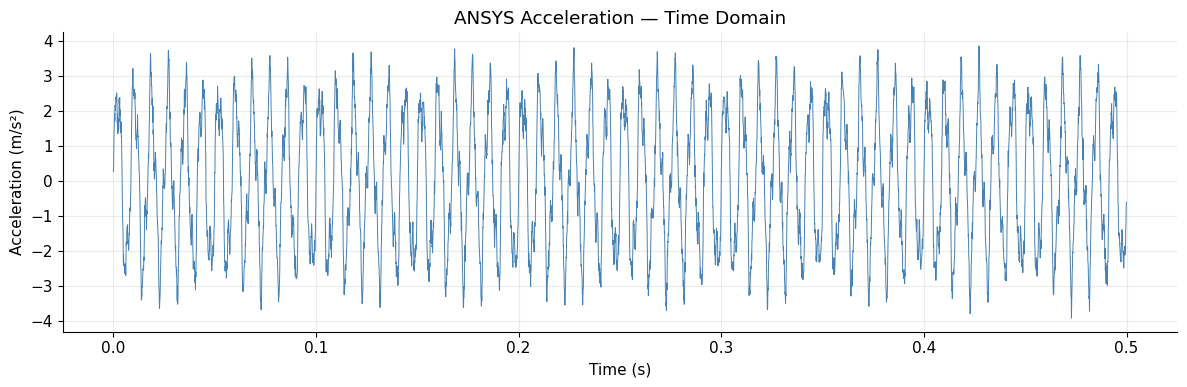

Mean (after removal) : 0.000000  ← should be ~0
Peak acceleration    : 3.9277 m/s²


In [3]:
# Remove DC offset (mean subtraction) — important before FFT
signal = df["accel_ms2"].values - df["accel_ms2"].mean()

fig, ax = plt.subplots()
ax.plot(df["time_s"], signal, lw=0.7, color="steelblue")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Acceleration (m/s²)")
ax.set_title("ANSYS Acceleration — Time Domain")
plt.tight_layout()
plt.show()

print(f"Mean (after removal) : {signal.mean():.6f}  ← should be ~0")
print(f"Peak acceleration    : {np.max(np.abs(signal)):.4f} m/s²")

---
## Step 3 — Compute the FFT

Two important choices before computing:

**1. Remove the DC offset** (done above) — a non-zero mean creates a large spike at 0 Hz
that masks everything else.

**2. Apply a Hann window** — ANSYS time histories rarely start and end at zero.
The Hann window tapers the signal smoothly, preventing spectral leakage from
smearing energy across neighbouring frequency bins.

In [4]:
# Apply Hann window to reduce spectral leakage
window     = windows.hann(N)
sig_win    = signal * window

# Compute FFT
spectrum   = fft(sig_win)
freqs      = fftfreq(N, d=1/fs)

# Keep positive frequencies only (spectrum is symmetric)
pos        = freqs >= 0
freqs_pos  = freqs[pos]

# Normalise magnitude: factor of 2 recovers single-sided amplitude;
# divide by N for consistent scaling regardless of record length;
# Hann window correction factor = 2 (sum of window / N ≈ 0.5)
magnitude  = (2 / N) * np.abs(spectrum[pos]) * 2

print("FFT computed successfully.")
print(f"Frequency bins : {len(freqs_pos):,}")
print(f"Freq resolution: {freqs_pos[1] - freqs_pos[0]:.3f} Hz")

FFT computed successfully.
Frequency bins : 2,500
Freq resolution: 2.000 Hz


---
## Step 4 — Plot the Frequency Spectrum

The FFT output maps each frequency bin to the amplitude of that sinusoidal component
in the original signal. Peaks in this plot are the **natural frequencies (modes)**
of your structure, as excited in the ANSYS simulation.

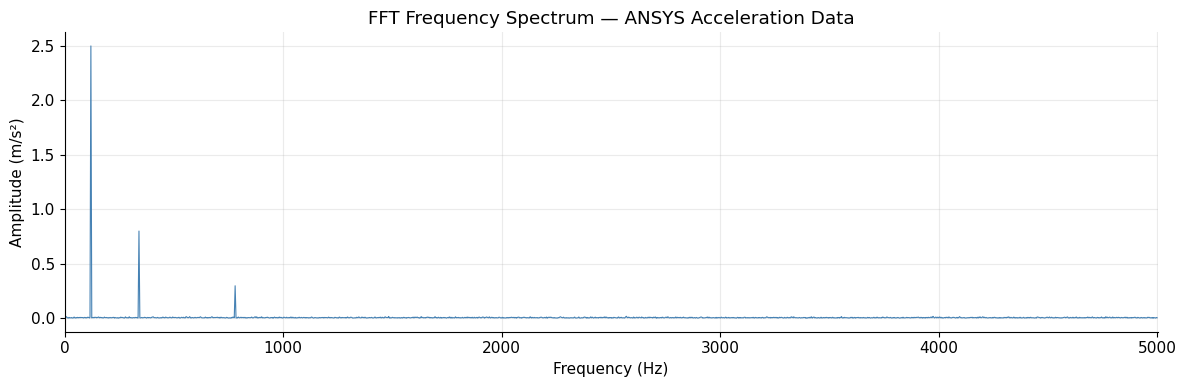

In [5]:
fig, ax = plt.subplots()
ax.plot(freqs_pos, magnitude, lw=0.8, color="steelblue")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Amplitude (m/s²)")
ax.set_title("FFT Frequency Spectrum — ANSYS Acceleration Data")
ax.set_xlim(0, fs / 2)
plt.tight_layout()
plt.show()

---
## Step 5 — Identify Dominant Frequencies

Rather than eyeballing the plot, detect peaks programmatically.
Compare them against your ANSYS modal analysis results — they should agree
within the frequency resolution of your time-history record.

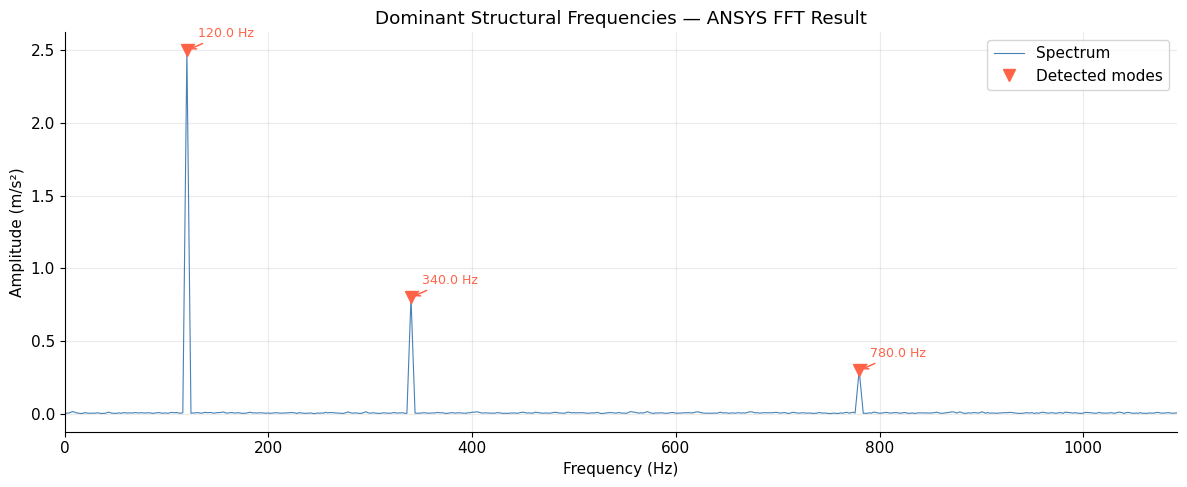

  Detected Modal Frequencies
  ──────────────────────────────────────
  Rank    Frequency (Hz)    Amplitude (m/s²)
  ──────────────────────────────────────
     1            120.00              2.4983
     2            340.00              0.7992
     3            780.00              0.2969
  ──────────────────────────────────────


In [6]:
# Detect peaks: adjust 'height' threshold to your signal's noise floor
peaks, props = find_peaks(
    magnitude,
    height     = magnitude.max() * 0.05,   # at least 5% of peak amplitude
    distance   = int(10 / (freqs_pos[1])), # minimum 10 Hz separation between peaks
    prominence = magnitude.max() * 0.03
)

# ── Annotated spectrum ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(freqs_pos, magnitude, lw=0.8, color="steelblue", label="Spectrum")
ax.plot(freqs_pos[peaks], magnitude[peaks],
        "v", color="tomato", ms=9, label="Detected modes")

for pk in peaks:
    ax.annotate(
        f"{freqs_pos[pk]:.1f} Hz",
        xy     = (freqs_pos[pk], magnitude[pk]),
        xytext = (8, 10), textcoords="offset points",
        fontsize= 9, color="tomato",
        arrowprops=dict(arrowstyle="->", color="tomato", lw=1.1)
    )

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Amplitude (m/s²)")
ax.set_title("Dominant Structural Frequencies — ANSYS FFT Result")
ax.set_xlim(0, min(fs/2, freqs_pos[peaks].max() * 1.4))
ax.legend()
plt.tight_layout()
plt.show()

# ── Summary table ─────────────────────────────────────────────────────────
print("  Detected Modal Frequencies")
print("  " + "─" * 38)
print(f"  {'Rank':>4}  {'Frequency (Hz)':>16}  {'Amplitude (m/s²)':>18}")
print("  " + "─" * 38)
sorted_peaks = sorted(peaks, key=lambda p: magnitude[p], reverse=True)
for rank, pk in enumerate(sorted_peaks, 1):
    print(f"  {rank:>4}  {freqs_pos[pk]:>16.2f}  {magnitude[pk]:>18.4f}")
print("  " + "─" * 38)

---
## Tips for ANSYS Data Specifically

**Sampling rate from ANSYS:**
Your FFT frequency resolution = 1 / (total time). For sharp peaks, use longer
time histories. ANSYS harmonic analysis output at small time steps gives better
Nyquist headroom.

**Transient start-up:**
If your ANSYS simulation has a ramp-up phase, trim the first few cycles before
applying the FFT — they are not steady-state and will smear your spectrum.

**Matching modal analysis:**
Cross-check detected peaks against your ANSYS Modal analysis natural frequencies.
They should agree within ±(fs/N) Hz. Large discrepancies suggest the excitation
didn't adequately activate that mode.

**Units:**
ANSYS exports acceleration in m/s² by default. If your data is in mm/s² or g,
adjust the y-axis label accordingly — the FFT math is identical.

---
*AnalytiCode — For @mechanicalengineer8961*